# Email / SMS Spam Detection with Machine Learning
**Oasis Infobyte SIP | Track: Data Science | Task 4**

**Objective:** Build a Natural Language Processing (NLP) binary classifier that separates **spam** messages from legitimate (**ham**) messages.

**Tech stack:** Python, pandas, scikit-learn (TF-IDF, Naive Bayes, Logistic Regression, SVM), `re` for text cleaning, matplotlib, seaborn, Jupyter Notebook

**Dataset:** SMS Spam Collection (UCI / Kaggle), 5,572 labelled text messages. This is the classic dataset recommended for this task; spam detection works the same way for emails and SMS because it is a text classification problem.

## 1. Import libraries

In [1]:
import re
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 2. Load the data and check class distribution
The file is not UTF-8 encoded, so `latin-1` is used. It has two useful columns (`v1` = label, `v2` = message) and three almost-empty extra columns, which are dropped.

In [2]:
raw = pd.read_csv("spam.csv", encoding="latin-1")
print("Raw shape:", raw.shape)
print("Non-empty values in the 3 extra columns:", raw[["Unnamed: 2", "Unnamed: 3", "Unnamed: 4"]].notna().sum().tolist())

df = raw[["v1", "v2"]].rename(columns={"v1": "label", "v2": "message"})
print("\nNull values:\n", df.isnull().sum())
print(df.head())

Raw shape: (5572, 5)
Non-empty values in the 3 extra columns: [50, 12, 6]

Null values:
 label      0
message    0
dtype: int64
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


       messages  percentage
label                      
ham        4825       86.59
spam        747       13.41


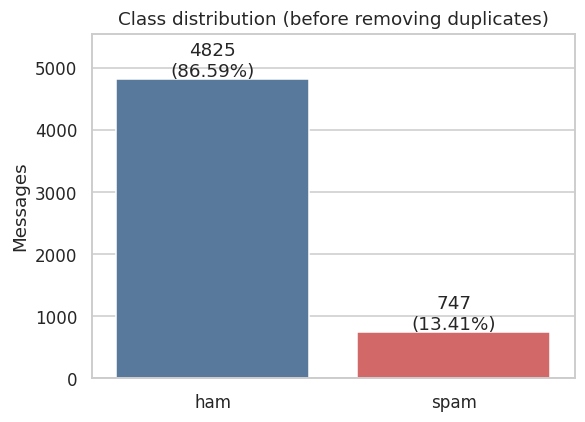

In [3]:
counts = df["label"].value_counts()
pct = (counts / len(df) * 100).round(2)
print(pd.DataFrame({"messages": counts, "percentage": pct}))

fig, ax = plt.subplots(figsize=(5.5, 4))
sns.barplot(x=counts.index, y=counts.values, palette=["#4c78a8", "#e45756"], ax=ax)
for i, (c, p) in enumerate(zip(counts.values, pct.values)):
    ax.text(i, c + 40, f"{c}\n({p}%)", ha="center")
ax.set_title("Class distribution (before removing duplicates)")
ax.set_ylabel("Messages"); ax.set_xlabel(""); ax.set_ylim(0, counts.max() * 1.15)
plt.tight_layout()
plt.show()

**Observation:** The data is **imbalanced**: only about 13% of the messages are spam. A model that always said "ham" would already be about 87% accurate, so accuracy alone is misleading here. Precision, recall and F1 for the spam class matter more.

### 2.1 Duplicate messages

In [4]:
dups = df.duplicated().sum()
print("Exact duplicate messages:", dups)
print("\nDuplicates by label:\n", df[df.duplicated()]["label"].value_counts())

df = df.drop_duplicates().reset_index(drop=True)
print("\nShape after removing duplicates:", df.shape)
print(df["label"].value_counts())

Exact duplicate messages: 403

Duplicates by label:
 label
ham     309
spam     94
Name: count, dtype: int64

Shape after removing duplicates: (5169, 2)
label
ham     4516
spam     653
Name: count, dtype: int64


**Why remove duplicates?** If the same message appeared in both the training and the test set, the model would be tested on something it had already memorised and the scores would look better than they really are. Duplicates are removed **before** splitting the data.

## 3. Exploratory analysis: message length

      n_chars        n_words       
         mean median    mean median
label                              
ham      70.5   52.0    14.1   11.0
spam    137.9  149.0    23.7   25.0


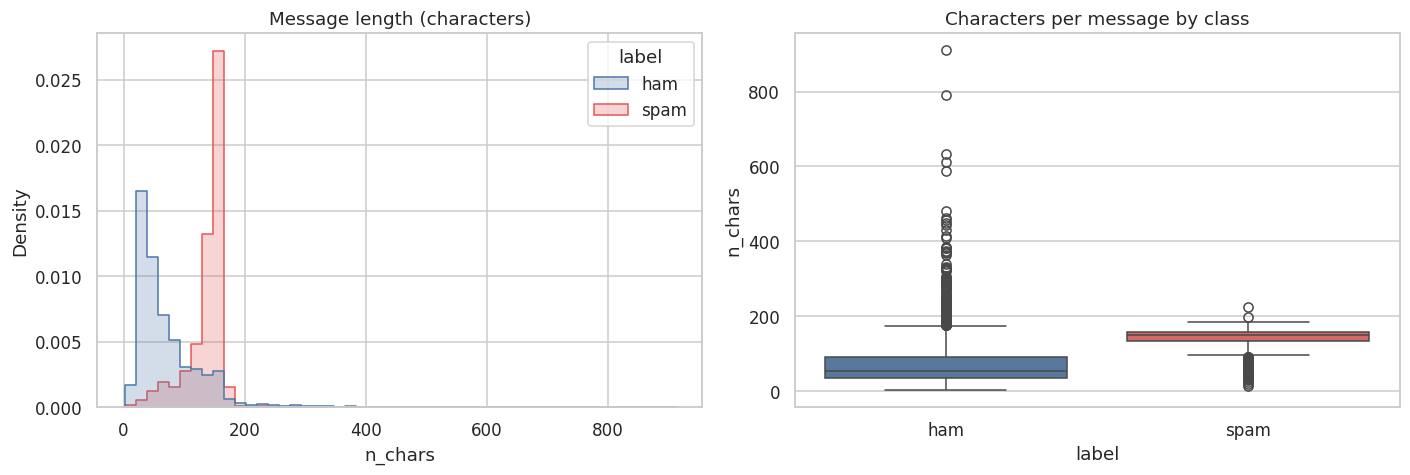

In [5]:
df["n_chars"] = df["message"].str.len()
df["n_words"] = df["message"].str.split().str.len()
print(df.groupby("label")[["n_chars", "n_words"]].agg(["mean", "median"]).round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(data=df, x="n_chars", hue="label", bins=50, palette={"ham": "#4c78a8", "spam": "#e45756"},
             element="step", stat="density", common_norm=False, ax=axes[0])
axes[0].set_title("Message length (characters)")
sns.boxplot(data=df, x="label", y="n_chars", palette={"ham": "#4c78a8", "spam": "#e45756"}, ax=axes[1])
axes[1].set_title("Characters per message by class")
plt.tight_layout()
plt.show()

**Observation:** Spam messages are clearly **longer** than ham messages on average (they usually contain a full offer, a price and a phone number), while ham messages are short and conversational. Length alone is not enough to classify a message, but it shows that the two classes use language differently.

## 4. Text preprocessing pipeline
Steps applied to every message:
1. **Lowercase** conversion
2. **Punctuation removal** (everything except letters and digits becomes a space). Digits are kept on purpose because prices, short codes and phone numbers are strong spam signals.
3. **Stopword removal** (very common words such as "the", "is", "and" that carry little meaning)

Stemming / lemmatisation is optional in the task and is skipped here to keep the vocabulary readable.

In [6]:
STOPWORDS = set("""
i me my myself we our ours ourselves you your yours yourself yourselves he him his himself she her hers herself
it its itself they them their theirs themselves what which who whom this that these those am is are was were be
been being have has had having do does did doing a an the and but if or because as until while of at by for with
about against between into through during before after above below to from up down in out on off over under again
further then once here there when where why how all any both each few more most other some such no nor not only
own same so than too very s t can will just don should now
""".split())

def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)           # remove punctuation / symbols
    tokens = [w for w in text.split() if w not in STOPWORDS]
    return " ".join(tokens)

df["clean"] = df["message"].apply(clean_text)
for i in [0, 2, 5]:
    print("ORIGINAL:", df.loc[i, "message"])
    print("CLEANED :", df.loc[i, "clean"], "\n")

ORIGINAL: Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...
CLEANED : go jurong point crazy available bugis n great world la e buffet cine got amore wat 

ORIGINAL: Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
CLEANED : free entry 2 wkly comp win fa cup final tkts 21st may 2005 text fa 87121 receive entry question std txt rate c apply 08452810075over18 

ORIGINAL: FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, å£1.50 to rcv
CLEANED : freemsg hey darling 3 week word back d like fun still tb ok xxx std chgs send 1 50 rcv 



## 5. Feature extraction with TF-IDF
**What does TF-IDF measure?** A computer cannot read words, so each message is turned into numbers. **TF-IDF** (Term Frequency x Inverse Document Frequency) gives every word in a message a weight:
- **TF** (term frequency): how often the word appears in this message. A word that is repeated is probably important for that message.
- **IDF** (inverse document frequency): how rare the word is across all messages. Words that appear in almost every message (like "ok") get a low weight, rare and distinctive words (like "claim" or "prize") get a high weight.

So a word gets a high TF-IDF score when it is frequent in one message but rare overall, which is exactly what makes it a good clue about the class. Unigrams and bigrams (single words and pairs such as "free entry") are used. The vectorizer is placed inside a scikit-learn pipeline so it is **fitted on training data only**, which avoids leaking information from the test set.

## 6. Train / test split (80 / 20)
`stratify` keeps the same spam percentage in both sets.

In [7]:
X = df["clean"]
y = (df["label"] == "spam").astype(int)      # spam = 1, ham = 0

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
print("Train:", X_train.shape[0], "messages | spam share: %.1f%%" % (y_train.mean() * 100))
print("Test :", X_test.shape[0], "messages | spam share: %.1f%%" % (y_test.mean() * 100))

Train: 4135 messages | spam share: 12.6%
Test : 1034 messages | spam share: 12.7%


## 7. Train the classifiers
Three models, each combined with its own TF-IDF vectoriser in a pipeline:
1. **Multinomial Naive Bayes**: the standard baseline for text classification
2. **Logistic Regression** (with `class_weight="balanced"` to compensate for the imbalance)
3. **Linear SVM** (also class-weighted)

In [8]:
def tfidf():
    return TfidfVectorizer(ngram_range=(1, 2), min_df=2)

models = {
    "Multinomial Naive Bayes": make_pipeline(tfidf(), MultinomialNB(alpha=0.1)),
    "Logistic Regression": make_pipeline(tfidf(), LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)),
    "Linear SVM": make_pipeline(tfidf(), LinearSVC(class_weight="balanced", random_state=RANDOM_STATE)),
}
for name, m in models.items():
    m.fit(X_train, y_train)
print("Trained", len(models), "models.")

Trained 3 models.


## 8. Evaluation: accuracy, precision, recall, F1 and confusion matrix
Precision, recall and F1 are reported for the **spam** class.

Multinomial Naive Bayes
              precision    recall  f1-score   support

         ham      0.981     0.996     0.988       903
        spam      0.966     0.870     0.916       131

    accuracy                          0.980      1034
   macro avg      0.974     0.933     0.952      1034
weighted avg      0.979     0.980     0.979      1034

Logistic Regression
              precision    recall  f1-score   support

         ham      0.983     0.986     0.985       903
        spam      0.899     0.885     0.892       131

    accuracy                          0.973      1034
   macro avg      0.941     0.936     0.938      1034
weighted avg      0.973     0.973     0.973      1034

Linear SVM
              precision    recall  f1-score   support

         ham      0.982     0.993     0.988       903
        spam      0.950     0.878     0.913       131

    accuracy                          0.979      1034
   macro avg      0.966     0.936     0.950      1034
weighted avg      0

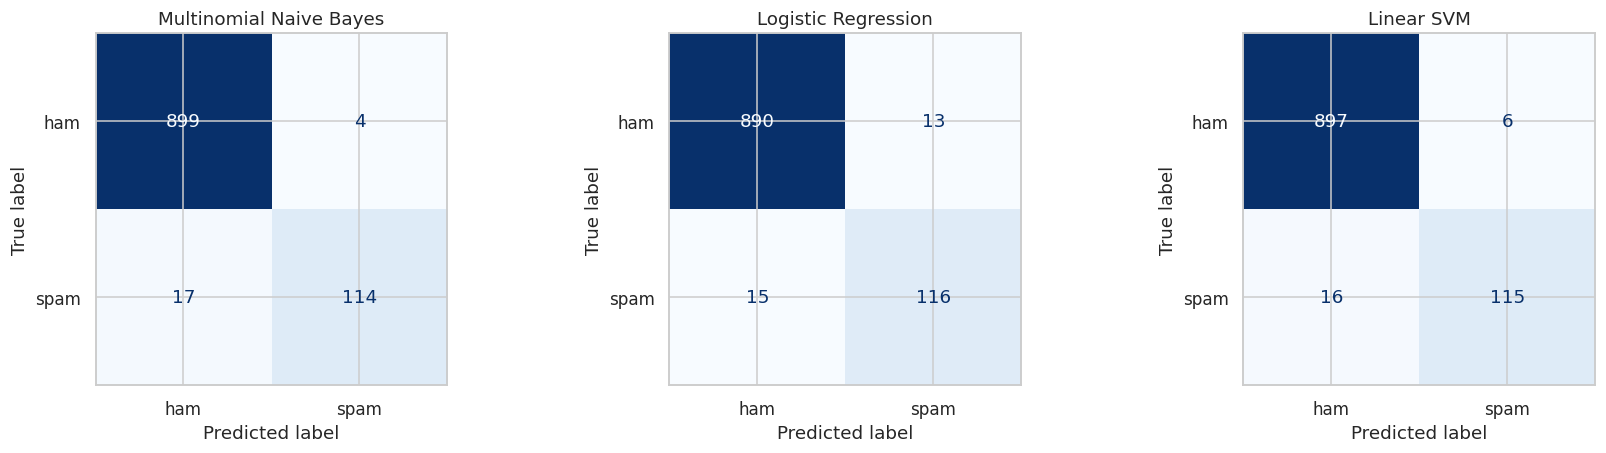

In [9]:
rows = []
for name, m in models.items():
    pred = m.predict(X_test)
    rows.append([name, accuracy_score(y_test, pred), precision_score(y_test, pred),
                 recall_score(y_test, pred), f1_score(y_test, pred)])
    print("=" * 62); print(name); print("=" * 62)
    print(classification_report(y_test, pred, target_names=["ham", "spam"], digits=3))

res = pd.DataFrame(rows, columns=["Model", "Accuracy", "Precision (spam)", "Recall (spam)", "F1 (spam)"])
print(res.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for ax, (name, m) in zip(axes, models.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, m.predict(X_test)), display_labels=["ham", "spam"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

**Cross-validation check.** The test set contains only about 130 spam messages, so one message changes the recall by almost 1 point. To make the comparison more reliable, each model is also scored with stratified 5-fold cross-validation (F1 of the spam class) on the whole data. Text is cleaned beforehand and TF-IDF is refitted inside every fold.

                  Model  CV precision  CV recall  CV F1 mean  CV F1 std
             Linear SVM        0.9541     0.9173      0.9350     0.0146
Multinomial Naive Bayes        0.9734     0.8943      0.9321     0.0126
    Logistic Regression        0.8948     0.9204      0.9071     0.0118


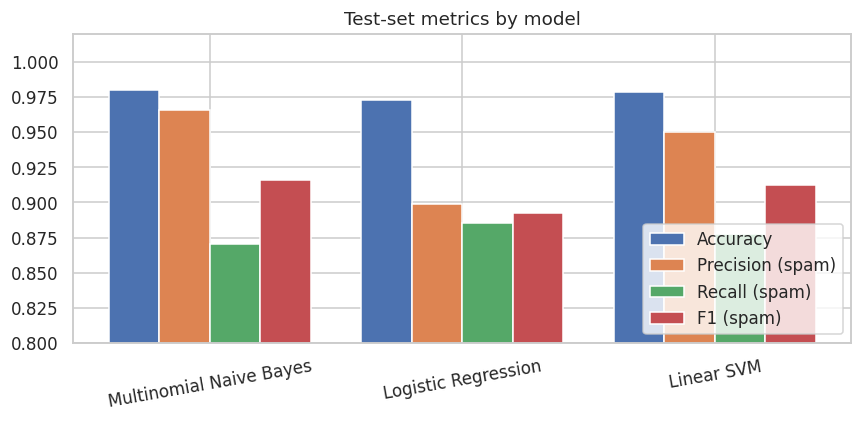

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, m in models.items():
    scores = cross_val_score(m, X, y, cv=cv, scoring="f1")
    rec = cross_val_score(m, X, y, cv=cv, scoring="recall")
    pre = cross_val_score(m, X, y, cv=cv, scoring="precision")
    cv_rows.append([name, pre.mean(), rec.mean(), scores.mean(), scores.std()])
cv_df = pd.DataFrame(cv_rows, columns=["Model", "CV precision", "CV recall", "CV F1 mean", "CV F1 std"])
cv_df = cv_df.sort_values("CV F1 mean", ascending=False).reset_index(drop=True)
print(cv_df.round(4).to_string(index=False))

plt.figure(figsize=(8, 4))
x = np.arange(len(res)); w = 0.2
for i, col in enumerate(["Accuracy", "Precision (spam)", "Recall (spam)", "F1 (spam)"]):
    plt.bar(x + (i - 1.5) * w, res[col], w, label=col)
plt.xticks(x, res["Model"], rotation=10); plt.ylim(0.8, 1.02); plt.legend(loc="lower right")
plt.title("Test-set metrics by model")
plt.tight_layout()
plt.show()

## 9. Discussion: why is recall particularly important for spam detection?
**Recall** answers: *of all the real spam messages, how many did the model catch?* It is `caught spam / (caught spam + missed spam)`.

A low recall means many spam messages slip through into the inbox. Those messages are not just annoying: they can contain phishing links, scams, fake prizes and premium-rate numbers, so every missed spam is a real risk for the user. That is why recall is important for a spam filter.

**But recall is only half of the story.** If a model simply marked everything as spam it would have 100% recall and be useless, because legitimate messages would be blocked. **Precision** (of the messages flagged as spam, how many really are spam) protects the user from losing important ham messages such as a bank code or a job offer. In practice, a real spam filter often values precision at least as much as recall, because wrongly blocking a good message can be worse than letting one spam through. The **F1 score** combines both, and the balance can be adjusted through the decision threshold.

## 10. Bonus: most common words in spam vs ham
(The `wordcloud` library was not available in this environment, so the same information is shown as word-frequency bar charts.)

Words most indicative of SPAM : claim, prize, 150p, co, co uk, 18, nokia, tone, guaranteed, 1000, 16, 500
Words most indicative of HAM  : gt, lt, lt gt, da, lor, lol, later, anything, really, sure, said, say


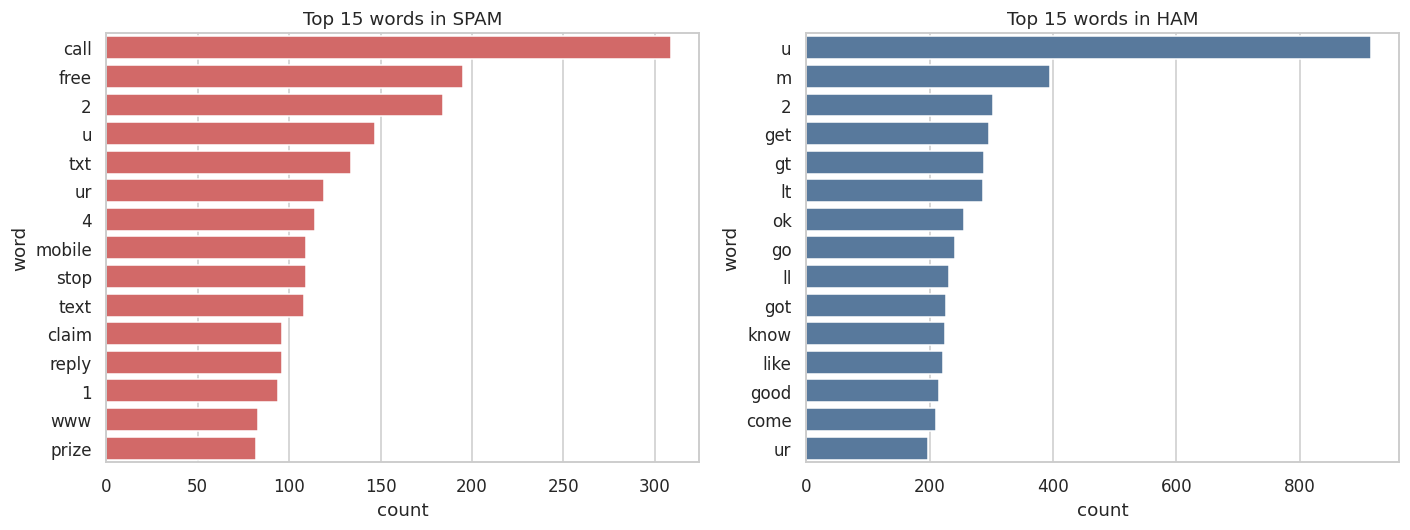

In [11]:
from collections import Counter

def top_words(series, n=15):
    c = Counter(" ".join(series).split())
    return pd.DataFrame(c.most_common(n), columns=["word", "count"])

spam_words = top_words(df.loc[df["label"] == "spam", "clean"])
ham_words = top_words(df.loc[df["label"] == "ham", "clean"])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(data=spam_words, y="word", x="count", color="#e45756", ax=axes[0]); axes[0].set_title("Top 15 words in SPAM")
sns.barplot(data=ham_words, y="word", x="count", color="#4c78a8", ax=axes[1]); axes[1].set_title("Top 15 words in HAM")
plt.tight_layout()
plt.show()

# words the Naive Bayes model finds most indicative of spam (log-probability ratio)
nb = models["Multinomial Naive Bayes"]
vec, clf = nb.steps[0][1], nb.steps[1][1]
vocab = np.array(vec.get_feature_names_out())
ratio = clf.feature_log_prob_[1] - clf.feature_log_prob_[0]
order = np.argsort(ratio)
print("Words most indicative of SPAM :", ", ".join(vocab[order[-12:]][::-1]))
print("Words most indicative of HAM  :", ", ".join(vocab[order[:12]]))

## 11. Conclusion: which model is the best?

| Model | Accuracy (test) | Precision (spam) | Recall (spam) | F1 (spam) | CV F1 (5-fold) |
|---|---|---|---|---|---|
| Linear SVM | 97.9% | 95.0% | 87.8% | 91.3% | **93.5%** |
| Multinomial Naive Bayes | **98.0%** | **96.6%** | 87.0% | **91.6%** | 93.2% |
| Logistic Regression | 97.3% | 89.9% | **88.6%** | 89.2% | 90.7% |

*(Test set: 1,034 messages, 131 of them spam.)*

**What the results show**
- All three models reach about **97-98% accuracy**, but accuracy is not the key number because only about 13% of messages are spam. The spam-class **F1 score is about 0.89-0.92**.
- **Multinomial Naive Bayes** is the strongest on the test split (highest precision, only 4 ham messages wrongly flagged as spam, 17 spam missed). **Linear SVM** is essentially tied with it (6 false alarms, 16 spam missed) and has the best 5-fold cross-validated F1 (0.935 vs 0.932).
- **Logistic Regression** catches the most spam (highest recall, 15 missed) but pays for it with the lowest precision (13 legitimate messages wrongly flagged), so its F1 is the lowest.

**Declared best model: Linear SVM** (highest cross-validated F1, very good precision and recall on the test set). Naive Bayes is practically as good (the gap is far smaller than the fold-to-fold variation of about 1.3-1.5 points), and is the better choice if **avoiding false alarms** matters most. If **catching every possible spam** matters most, Logistic Regression has the best recall.

**Reading the recall result:** recall is around 87-92%, which means roughly 1 spam message in 10 still gets through, and the discussion in section 9 explains why that trade-off against precision matters.

**Limitations:** this is a relatively small, older SMS dataset, so the scores will not transfer directly to modern email spam. Duplicate messages were removed, TF-IDF with bigrams was used without stemming, and the models were not tuned heavily. Possible next steps: hyper-parameter tuning, stemming/lemmatisation, character n-grams, and adjusting the decision threshold.


## 12. Predicting new messages (demo)

In [12]:
best_name = cv_df.loc[0, "Model"]
best_model = models[best_name]

samples = [
    "WINNER!! You have been selected to receive a free prize. Call 09061701461 now to claim your reward",
    "Hey, are we still meeting for lunch tomorrow at 1?",
    "URGENT! Your mobile number has won 2000 cash. Text CLAIM to 80086 to collect",
    "Can you send me the notes from yesterday's class? Thanks",
]
print("Model used:", best_name, "\n")
for s in samples:
    p = best_model.predict(pd.Series([clean_text(s)]))[0]
    print(("SPAM" if p == 1 else "HAM ").ljust(5), "|", s)

Model used: Linear SVM 

SPAM  | WINNER!! You have been selected to receive a free prize. Call 09061701461 now to claim your reward
HAM   | Hey, are we still meeting for lunch tomorrow at 1?
SPAM  | URGENT! Your mobile number has won 2000 cash. Text CLAIM to 80086 to collect
HAM   | Can you send me the notes from yesterday's class? Thanks
